In [2]:
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)

sys.path.append("..")
from src import preprocessing as pp

sns.set_theme(style="whitegrid")

X = np.load("../data/processed/X_scaled.npy")
X_pca = np.load("../data/processed/X_pca.npy")
df = pd.read_csv("../data/processed/loans_clean.csv", parse_dates=["IssueDate"])

rng = np.random.default_rng(42)
work_idx = rng.choice(len(X), size=100_000, replace=False)
np.save("../data/processed/kmeans_work_idx.npy", work_idx)

# Two versions of the data to cluster: all 15 features, or the 5 PCA components
spaces = {"All features (scaled)": X[work_idx], "PCA components": X_pca[work_idx]}

In [3]:
K_VALUES = range(2, 13)


def evaluate_k(data, k):
    model = KMeans(n_clusters=k, n_init=5, random_state=42).fit(data)
    labels = model.labels_
    return {
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(data, labels, sample_size=10_000, random_state=42),
        "davies_bouldin": davies_bouldin_score(data, labels),
        "calinski_harabasz": calinski_harabasz_score(data, labels),
    }


sweeps = {}
for name, data in spaces.items():
    sweeps[name] = pd.DataFrame([evaluate_k(data, k) for k in K_VALUES]).set_index("k")
    print(name)
    print(sweeps[name].round(3), "\n")

All features (scaled)
       inertia  silhouette  davies_bouldin  calinski_harabasz
k                                                            
2   426670.594       0.179           1.947          24232.440
3   376936.125       0.173           1.772          20311.776
4   334156.188       0.168           1.610          19541.934
5   302227.625       0.166           1.533          18845.568
6   280154.312       0.160           1.500          17839.936
7   263523.844       0.156           1.537          16856.368
8   250424.609       0.153           1.474          15951.132
9   240688.391       0.151           1.526          15027.265
10  231895.094       0.148           1.583          14285.215
11  224197.922       0.141           1.577          13641.226
12  217425.922       0.139           1.551          13070.378 

PCA components
       inertia  silhouette  davies_bouldin  calinski_harabasz
k                                                            
2   398587.594       0.190     

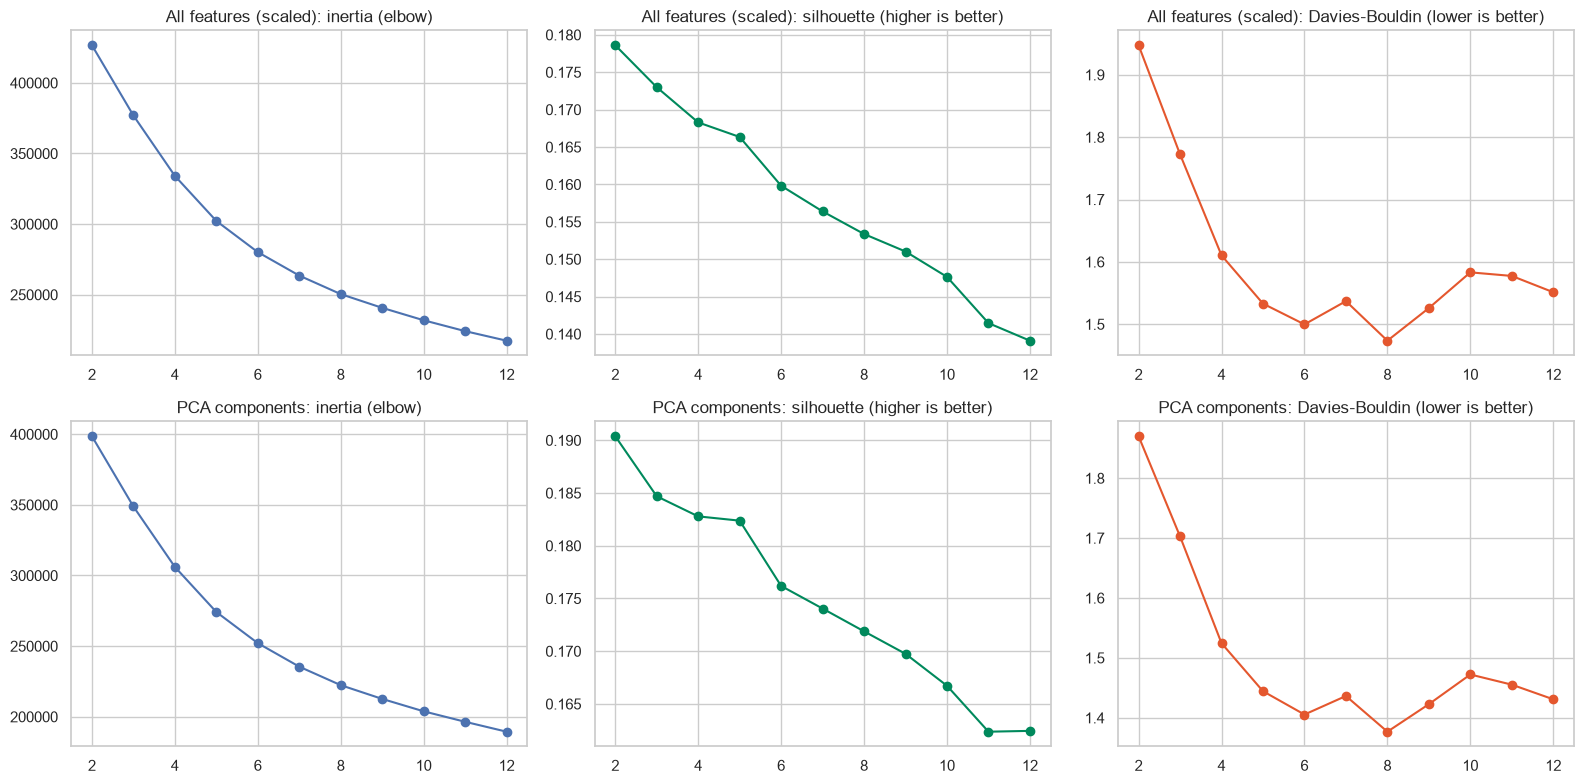

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, (name, table) in enumerate(sweeps.items()):
    axes[row, 0].plot(table.index, table["inertia"], marker="o")
    axes[row, 0].set_title(f"{name}: inertia (elbow)")
    axes[row, 1].plot(table.index, table["silhouette"], marker="o", color="#00895C")
    axes[row, 1].set_title(f"{name}: silhouette (higher is better)")
    axes[row, 2].plot(table.index, table["davies_bouldin"], marker="o", color="#E4572E")
    axes[row, 2].set_title(f"{name}: Davies-Bouldin (lower is better)")
plt.tight_layout()
plt.savefig("../docs/figures/13_kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
def seed_stability(data, k, seeds=(1, 2, 3, 4, 5)):
    """Cluster with 5 different random starts and measure how much they agree (1 = identical)."""
    labelings = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(data) for s in seeds]
    return float(np.mean([adjusted_rand_score(labelings[0], other) for other in labelings[1:]]))


stability = pd.DataFrame(
    {name: [seed_stability(data, k) for k in range(3, 9)] for name, data in spaces.items()},
    index=range(3, 9),
)
stability.round(3)

,All features (scaled),PCA components
3,0.380,0.535
4,0.472,0.511
5,0.689,0.813
6,0.960,0.851
7,0.569,0.655
8,0.972,0.575


In [6]:
CANDIDATE_K = 5          # EDIT: your best guess after looking at Cells 3 and 4

sample_features = pp.prepare_features(df.iloc[work_idx])
weight_results, weight_labels = [], {}

for weight in (0.0, 0.5, 1.0):
    matrix = pp.build_preprocessor(categorical_weight=weight).fit_transform(sample_features)
    labels = KMeans(n_clusters=CANDIDATE_K, n_init=5, random_state=42).fit_predict(matrix)
    weight_labels[weight] = labels
    weight_results.append({
        "category_weight": weight,
        "silhouette": silhouette_score(matrix, labels, sample_size=10_000, random_state=42),
    })

weight_table = pd.DataFrame(weight_results)
weight_table["agreement_with_0.5 (ARI)"] = [
    adjusted_rand_score(weight_labels[0.5], weight_labels[w]) for w in weight_table["category_weight"]]
print(weight_table.round(3))

pca_labels = KMeans(n_clusters=CANDIDATE_K, n_init=5, random_state=42).fit_predict(spaces["PCA components"])
print("\nAgreement between clustering on PCA components and on all features:",
      round(adjusted_rand_score(pca_labels, weight_labels[0.5]), 3))

   category_weight  silhouette  agreement_with_0.5 (ARI)
0              0.0       0.183                     0.974
1              0.5       0.166                     1.000
2              1.0       0.136                     0.911

Agreement between clustering on PCA components and on all features: 0.99


In [13]:
K_FINAL = 5              # EDIT: your decision, from Cells 3 to 5
X_final = X_pca          # use X instead to cluster on all 15 features

final_model = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X_final)
labels = final_model.labels_
print("Cluster sizes:", np.bincount(labels))

Cluster sizes: [345055 286607 155730 293888 266401]


In [8]:
df["Cluster"] = labels

profile = df.groupby("Cluster")[["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]].median().round(1)
profile["share_of_loans"] = df["Cluster"].value_counts(normalize=True).sort_index().round(3)
profile

,Income,LoanAmount,DTI,CreditScore,EmploymentLength,share_of_loans
Cluster,,,,,,
0,88000.0,17700.0,15.1,687.0,10.0,0.256
1,51000.0,12000.0,28.5,687.0,8.0,0.213
2,75000.0,14000.0,14.4,757.0,7.0,0.116
3,41000.0,5650.0,15.2,682.0,4.0,0.218
4,85000.0,17500.0,15.8,687.0,2.0,0.198


In [9]:
np.save("../data/processed/labels_kmeans.npy", labels)
joblib.dump(final_model, "../models/kmeans.joblib")

with open("../models/clustering_info.json", "w") as file:
    json.dump({"k": K_FINAL, "feature_space": "PCA" if X_final is X_pca else "all features"}, file)

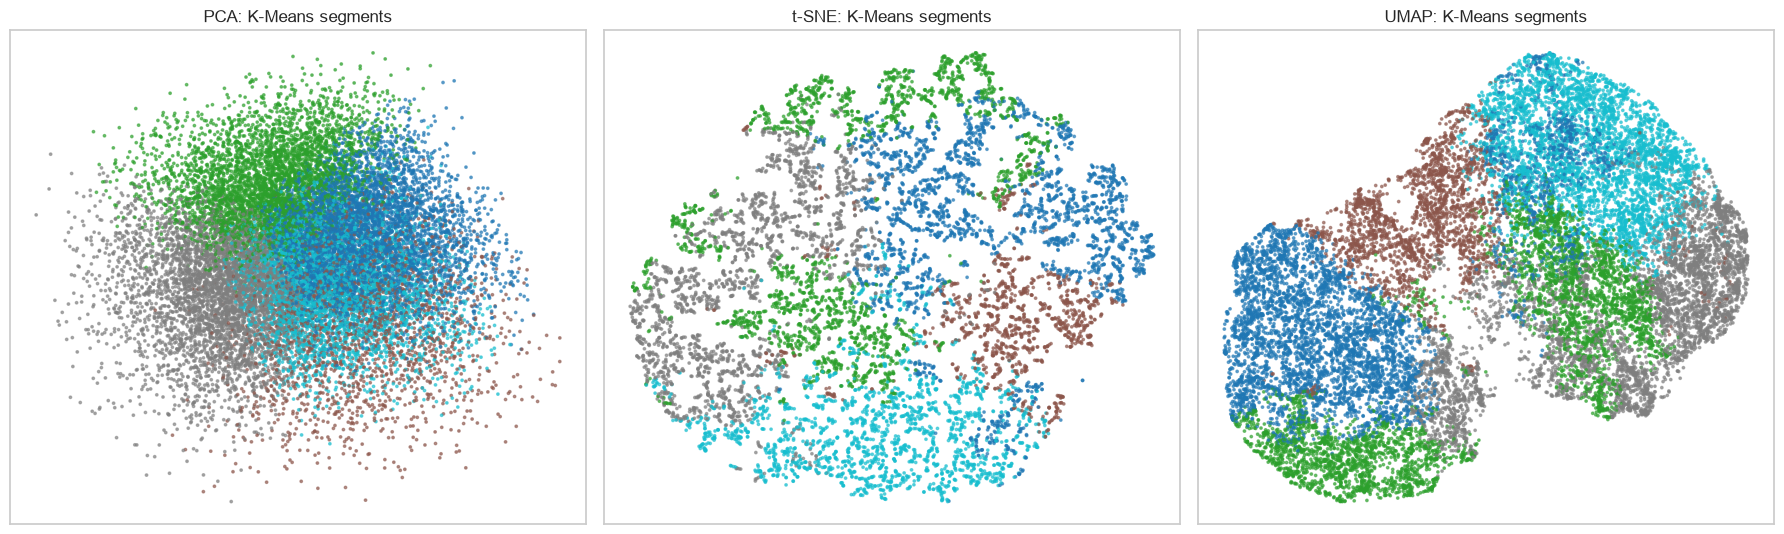

In [14]:
tsne_embedding = np.load("../data/processed/tsne_embedding.npy")
umap_embedding = np.load("../data/processed/umap_embedding.npy")
sample_idx = np.load("../data/processed/sample_idx.npy")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
panels = [
    (X_pca[sample_idx][:, :2], sample_idx, "PCA"),
    (tsne_embedding, sample_idx[:10_000], "t-SNE"),
    (umap_embedding, sample_idx, "UMAP"),
]
for ax, (embedding, idx, title) in zip(axes, panels):
    ax.scatter(embedding[:, 0], embedding[:, 1], c=labels[idx], cmap="tab10", s=3, alpha=0.6)
    ax.set_title(f"{title}: K-Means segments")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig("../docs/figures/14_kmeans_on_maps.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def split_half_stability(data, k, size=100_000, seed=0):
    """Fit K-Means on two separate samples, label a third sample with both, and compare (1 = identical)."""
    order = np.random.default_rng(seed).permutation(len(data))
    first, second, third = order[:size], order[size:2 * size], order[2 * size:3 * size]
    model_a = KMeans(n_clusters=k, n_init=10, random_state=1).fit(data[first])
    model_b = KMeans(n_clusters=k, n_init=10, random_state=2).fit(data[second])
    return adjusted_rand_score(model_a.predict(data[third]), model_b.predict(data[third]))


pd.Series({k: round(split_half_stability(X_pca, k), 3) for k in range(4, 9)}, name="split-half ARI")

4    0.981
5    0.950
6    0.906
7    0.942
8    0.962
Name: split-half ARI, dtype: float64

In [12]:
def profile_for_k(k):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(spaces["PCA components"])
    sample = df.iloc[work_idx].assign(Cluster=model.labels_)
    table = sample.groupby("Cluster")[["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]].median().round(1)
    table["share"] = sample["Cluster"].value_counts(normalize=True).sort_index().round(3)
    return table.sort_values("CreditScore")


display(profile_for_k(5))
display(profile_for_k(6))

,Income,LoanAmount,DTI,CreditScore,EmploymentLength,share
Cluster,,,,,,
0,40000.0,6000.0,16.1,682.0,3.0,0.230
1,87500.0,16000.0,14.3,687.0,10.0,0.243
2,85000.0,18000.0,16.2,687.0,2.0,0.199
3,54000.0,12725.0,28.2,687.0,9.0,0.212
4,75000.0,14000.0,14.3,757.0,7.0,0.116


,Income,LoanAmount,DTI,CreditScore,EmploymentLength,share
Cluster,,,,,,
1,38000.0,6075.0,19.0,682.0,2.0,0.180
5,60000.0,7800.0,13.5,682.0,10.0,0.168
2,85000.0,17887.5,15.5,687.0,2.0,0.190
0,56000.0,14600.0,28.4,687.0,9.0,0.188
4,103886.0,22000.0,15.4,692.0,10.0,0.169
3,72000.0,13000.0,14.0,762.0,6.0,0.105
